# Aula 9 - Testes Não Paramétricos

## 1. Preparando o ambiente

In [30]:
# importa as bibliotecas e define o tema dos gráficos
import numpy as np                              
import pandas as pd                            
import matplotlib.pyplot as plt                
import seaborn as sns                         
from matplotlib.colors import ListedColormap
from scipy import stats                        

sns.set_theme(style="whitegrid", palette="colorblind")

In [31]:
# função auxiliar que resume o resultado de um teste em uma linha
# os testes do scipy devolvem um objeto com .statistic e .pvalue (e às vezes .df)
def report(name, result, stat="estatística"):
  # começa a lista de partes com o valor da estatística (t, U, r, ρ...) com 3 casas
  parts = [f"{stat} = {result.statistic:.3f}"]
  # só alguns testes têm graus de liberdade (ex.: teste t) hasattr checa se o atributo existe
  if hasattr(result, "df"):
      parts.append(f"gl = {result.df:.4g}")
  p = result.pvalue
  # p-valores muito pequenos viram "p < 0.001" em vez de mostrar 0.000
  parts.append("p < 0.001" if p < 0.001 else f"p = {p:.3f}")
  # junta tudo separado por " · " e imprime
  print(f"{name}: " + " · ".join(parts))

## 2. Recapitulação

### 2.2 Revisão estendida: a distribuição Z

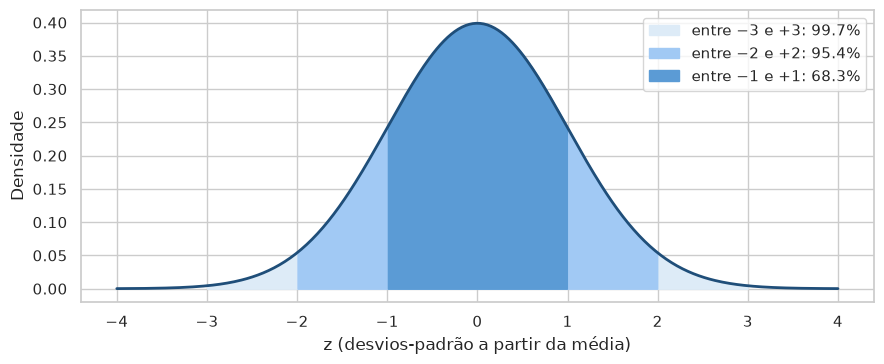

In [ ]:
# normal padrão (média 0, desvio 1) com as faixas de 1, 2 e 3 desvios-padrão
# cria 400 pontos igualmente espaçados entre -4 e 4 (o eixo x do gráfico)
grid = np.linspace(-4, 4, 400)
# stats.norm.pdf devolve a altura da curva normal padrão em cada ponto do grid
density = stats.norm.pdf(grid)

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(grid, density, color="#1F4E79", linewidth=2)   # desenha a curva
# pinta as faixas da mais larga (3 dp) para a mais estreita (1 dp),
# assim as mais estreitas ficam por cima e todas aparecem
for k, color in [(3, "#DDEBF7"), (2, "#A1C9F4"), (1, "#5B9BD5")]:
    # área entre -k e +k = área acumulada até +k menos a área acumulada até -k
    area = stats.norm.cdf(k) - stats.norm.cdf(-k)
    # fill_between pinta embaixo da curva só onde |z| <= k
    ax.fill_between(grid, density, where=np.abs(grid) <= k, color=color, label=f"entre −{k} e +{k}: {area:.1%}")
ax.set(xlabel="z (desvios-padrão a partir da média)", ylabel="Densidade", xticks=range(-4, 5))
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [33]:
# áreas da normal padrão e o caminho inverso, da área para o z
# cdf(z) = área à ESQUERDA de z -> P(Z <= -2)
print(f"P(Z ≤ −2) = {stats.norm.cdf(-2):.4f}")
# sf(z) = área à DIREITA de z (survival function = 1 - cdf) -> P(Z >= 2)
print(f"P(Z ≥ +2) = {stats.norm.sf(2):.4f}")
# ppf(área) faz o inverso da cdf: recebe uma área acumulada e devolve o z
# 0.975 de área à esquerda deixa 2,5% na cauda direita (e, por simetria, 2,5% na esquerda)
print(f"z que deixa 2,5% em cada cauda = {stats.norm.ppf(0.975):.2f}")
# os dois primeiros dão o mesmo valor porque a normal é simétrica em torno de 0

P(Z ≤ −2) = 0.0228
P(Z ≥ +2) = 0.0228
z que deixa 2,5% em cada cauda = 1.96


## 3. Tratamentos A e B, passo a passo

### 3.1 Os dados

In [ ]:
# tempos de internação (em dias) dos 8 pacientes de cada tratamento
# 120 em A eh um único paciente extremo (outlier) que vai bagunçar a média
days_a = [1, 2, 2, 3, 3, 4, 5, 120]
days_b = [4, 5, 5, 6, 6, 7, 8, 9]

# monta uma tabela "longa": uma linha por paciente, com o grupo e o valor
uti = pd.DataFrame(
  {
    # ["A"] * 8 repete "A" oito vezes o + concatena as duas listas
    "tratamento": ["A"] * len(days_a) + ["B"] * len(days_b),
    "dias": days_a + days_b,
  }
)

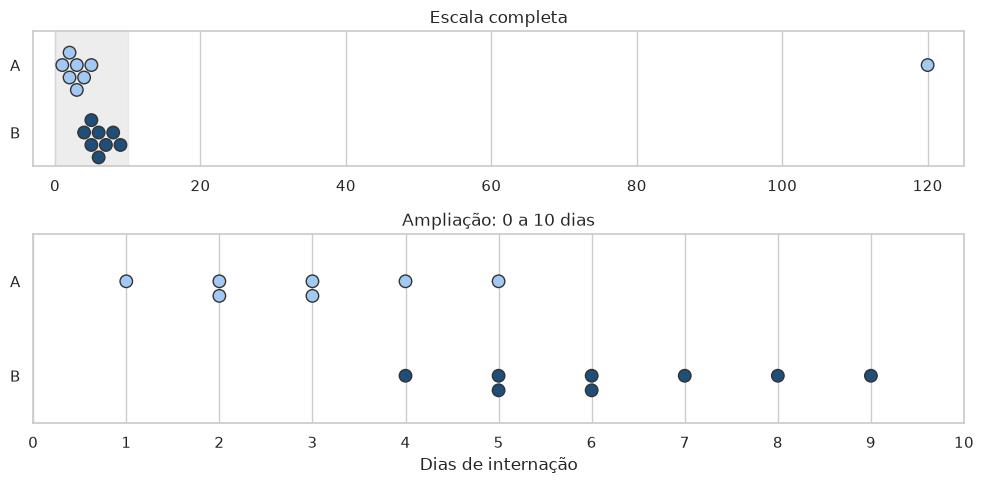

In [ ]:
# cada paciente em um ponto: escala completa (em cima) e ampliação de 0 a 10 dias (embaixo)
# height_ratios deixa o painel de baixo um pouco mais alto
fig, axes = plt.subplots(2, 1, figsize=(10, 5), height_ratios=[1, 1.4])

# zip junta cada eixo com o seu limite de x: o de cima vai até 125, o de baixo até 10
for ax, xlim in zip(axes, [(-3, 125), (0, 10)]):
  # swarmplot empilha os pontos com o mesmo valor lado a lado,
  # para que pacientes com o mesmo tempo não fiquem escondidos uns atrás dos outros
  sns.swarmplot(
    data=uti, x="dias", y="tratamento", hue="tratamento",
    palette={"A": "#A1C9F4", "B": "#1F4E79"}, size=9,
    edgecolor="#333333", linewidth=1, legend=False, ax=ax,
  )
  ax.set(xlim=xlim, ylabel="")

# faixa cinza no painel de cima marca a região que está ampliada no painel de baixo
axes[0].axvspan(0, 10, color="#DDDDDD", alpha=.5)
axes[0].set(title="Escala completa", xlabel="")
axes[1].set(title="Ampliação: 0 a 10 dias", xlabel="Dias de internação",
            xticks=range(11))
plt.tight_layout()
plt.show()
# lógica: na escala completa o 120 "esmaga" todo o resto na ampliação dá pra ver que, tirando ele, A tende a ficar MENOS tempo que B

### 3.2 As distribuições de cada grupo

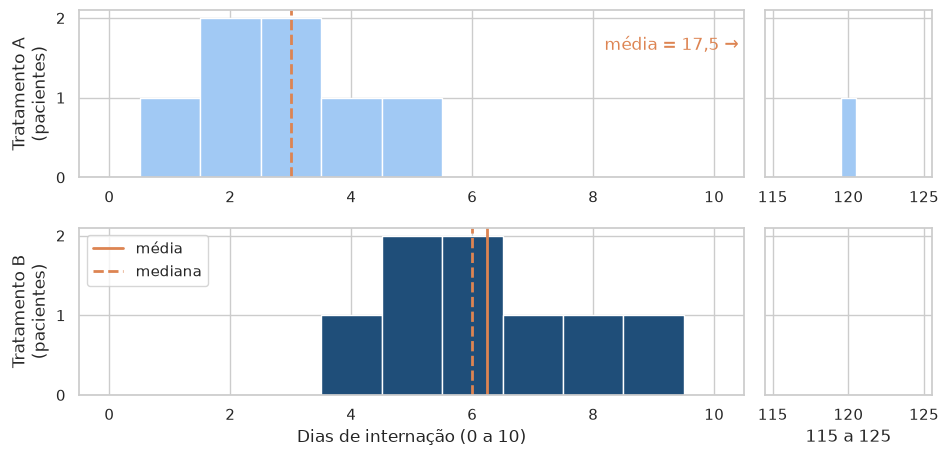

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5), sharey=True, gridspec_kw={"width_ratios": [4, 1]})

# cada linha de eixos recebe um grupo e uma cor
for row, (group, color) in zip(axes, [("A", "#A1C9F4"), ("B", "#1F4E79")]):
  # filtra só os dias do grupo atual
  values = uti.loc[uti["tratamento"] == group, "dias"]
  # cada eixo da linha mostra um trecho do eixo x
  for ax, (low, high) in zip(row, [(0, 10), (115, 125)]):
    # bordas das barras em meios dias (0.5, 1.5, ...) para que cada barra
    # fique centrada sobre um número inteiro de dias
    ax.hist(values, bins=np.arange(low - .5, high + 1), color=color, edgecolor="white")
    ax.set_xlim(low - .5, high + .5)
    # desenha linha contínua na média e tracejada na mediana
    for stat, style, label in [(values.mean(), "-", "média"), (values.median(), "--", "mediana")]:
        # mas só no trecho do eixo onde o valor realmente cai
        if low <= stat <= high:
          ax.axvline(stat, color="#DD8452", linestyle=style, linewidth=2, label=label)
  row[0].set(ylabel=f"Tratamento {group}\n(pacientes)", yticks=[0, 1, 2])

# a média de A (17,5) cai no buraco do eixo (entre 10 e 115), onde não há nenhum paciente,
# então só escrevemos uma seta indicando que ela está "pra lá"
axes[0, 0].annotate("média = 17,5 →", xy=(10.4, 1.6), ha="right", color="#DD8452")
axes[1, 0].legend(loc="upper left")
axes[1, 0].set_xlabel("Dias de internação (0 a 10)")
axes[1, 1].set_xlabel("115 a 125")
# aproxima as duas colunas para parecer um único eixo interrompido
fig.subplots_adjust(wspace=.05, hspace=.3)
plt.show()
# lógica: em A a média (17,5) não representa nenhum paciente típico a mediana (3) sim

### 3.3 Assimetria e medidas-resumo

In [ ]:
# coeficiente de assimetria (skewness) de cada grupo
for group in ["A", "B"]:
  values = uti.loc[uti["tratamento"] == group, "dias"]
  # stats.skew: perto de 0 = simétrico positivo = cauda longa à direita negativo = à esquerda
  print(f"Tratamento {group}: assimetria = {stats.skew(values):.2f}")
# A tem assimetria bem alta por causa do 120 B é quase simétrico

Tratamento A: assimetria = 2.26
Tratamento B: assimetria = 0.37


In [ ]:
# média, desvio-padrão, mediana e total de dias por tratamento
uti_summary = (
  uti
  .groupby("tratamento") # separa as linhas por grupo (A e B)
  .dias # pega só a coluna "dias"
  .agg(["mean", "std", "median", "sum"]) # calcula várias estatísticas de uma vez
  .round(2)
)

uti_summary
# pela média A parece pior (17,5 > 6,25), pela mediana A parece melhor (3 < 6)
# o desvio-padrão de A é enorme, sinal de que a média não é confiável aqui

,mean,std,median,sum
tratamento,,,,
A,17.50,41.43,3.0,140
B,6.25,1.67,6.0,50


### 3.4 O que diz a comparação de médias

In [39]:
# teste t de Welch comparando os tempos médios
# separa os dias de cada grupo em duas Series
group_a = uti.loc[uti["tratamento"] == "A", "dias"]
group_b = uti.loc[uti["tratamento"] == "B", "dias"]

# equal_var=False = versão de Welch, que não assume variâncias iguais nos grupos
welch_uti = stats.ttest_ind(group_a, group_b, equal_var=False)

report("t de Welch", welch_uti, stat="t")
# p alto (~0.47): o teste t não vê diferença. o outlier infla a variância de A,
# o erro-padrão fica enorme e "afoga" qualquer diferença -> motivação para um teste por postos

t de Welch: t = 0.767 · gl = 7.023 · p = 0.468


### 3.5 Construindo os postos

In [40]:
# a ideia do teste não paramétrico: trocar os valores pela sua POSIÇÃO na fila (posto/rank)
# assim o 120 vira só "o maior", sem importar se é 10 ou 1000

# passo 1: juntar os 16 pacientes e ordenar do menor para o maior tempo
# kind="stable" mantém a ordem original entre valores empatados
# reset_index(drop=True) renumera as linhas de 0 a 15 depois da ordenação
uti_sorted = uti.sort_values("dias", kind="stable").reset_index(drop=True)

# passo 2: numerar as posições de 1 a 16
positions = np.arange(1, len(uti_sorted) + 1)

# passo 3: calcular os postos, usando a média das posições nos empates
# ex.: dois pacientes com 2 dias ocupam as posições 2 e 3 -> ambos recebem posto 2.5
ranks = uti_sorted["dias"].rank(method="average")

# junta dados ordenados, posições e postos em uma tabela só (assign cria colunas novas)
ranked = uti_sorted.assign(posicao=positions, posto=ranks)

# .T transpõe a tabela para mostrar os 16 pacientes lado a lado (em colunas)
ranked.T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
tratamento,A,A,A,A,A,A,B,A,B,B,B,B,B,B,B,A
dias,1,2,2,3,3,4,4,5,5,5,6,6,7,8,9,120
posicao,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
posto,1.0,2.5,2.5,4.5,4.5,6.5,6.5,9.0,9.0,9.0,11.5,11.5,13.0,14.0,15.0,16.0


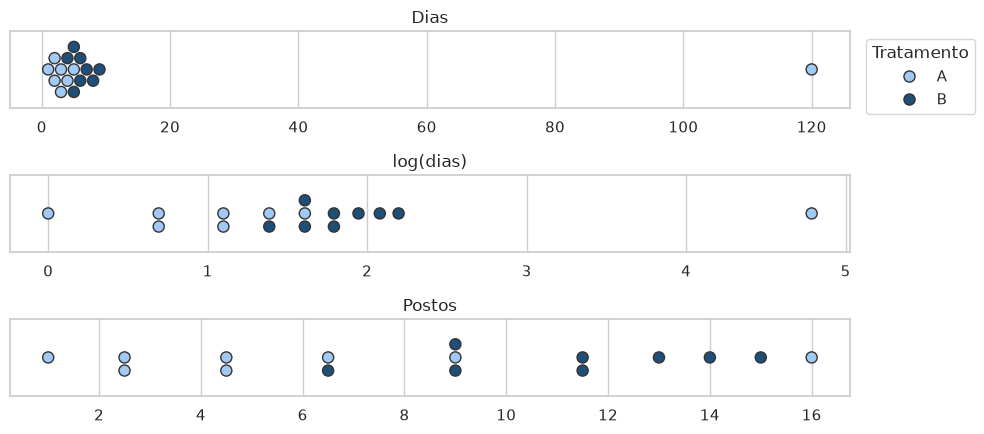

In [ ]:
# os mesmos 16 pacientes em três escalas: dias, log dos dias e postos
# dicionário: nome da escala -> valores nessa escala
scales = {
    "Dias": ranked["dias"],
    "log(dias)": np.log(ranked["dias"]), # log "encolhe" valores grandes, mas ainda mantém distância
    "Postos": ranked["posto"], # postos: distâncias viram sempre ~1, o outlier perde a força
}

fig, axes = plt.subplots(3, 1, figsize=(10, 4.5))
# .items() devolve pares (nome, valores) cada par vai para um eixo
for ax, (label, values) in zip(axes, scales.items()):
    sns.swarmplot(x=values, hue=ranked["tratamento"], size=8, ax=ax, palette={"A": "#A1C9F4", "B": "#1F4E79"}, edgecolor="#333333", linewidth=1, legend=(label == "Dias"))   # só mostra legenda no primeiro painel
    ax.set(title=label, xlabel="")

sns.move_legend(axes[0], "upper left", bbox_to_anchor=(1.01, 1), title="Tratamento")
plt.tight_layout()
plt.show()

### 3.6 Comparando os pares: a estatística $U$

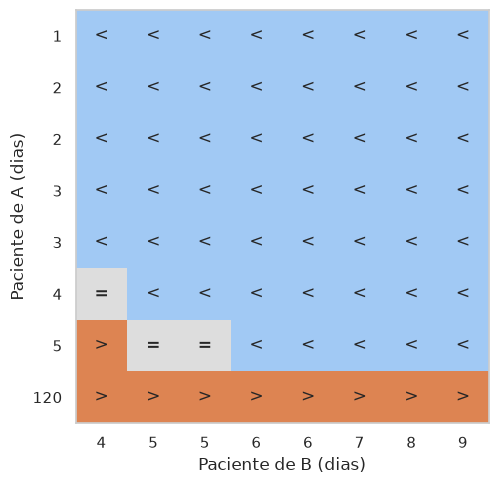

In [ ]:
# compara cada paciente de A com cada paciente de B (8 x 8 = 64 "duelos")
# np.subtract.outer monta a matriz de todas as diferenças a_i - b_j
# np.sign reduz cada diferença a -1 (A < B), 0 (empate) ou +1 (A > B)
duels = np.sign(np.subtract.outer(days_a, days_b))

fig, ax = plt.subplots(figsize=(6, 5))
# mapa de 3 cores: azul = A ficou menos tempo, cinza = empate, laranja = A ficou mais tempo
colors = ListedColormap(["#A1C9F4", "#DDDDDD", "#DD8452"])
# imshow desenha a matriz como uma imagem vmin/vmax fixam -1 -> 1ª cor e +1 -> 3ª cor
ax.imshow(duels, cmap=colors, vmin=-1, vmax=1)
# np.ndenumerate percorre a matriz devolvendo ((linha, coluna), valor)
for (i, j), value in np.ndenumerate(duels):
    # escreve o símbolo dentro de cada quadradinho (x = coluna j, y = linha i)
    ax.text(j, i, {-1: "<", 0: "=", 1: ">"}[value], ha="center", va="center")
    
ax.set(xticks=range(8), xticklabels=days_b, yticks=range(8), yticklabels=days_a,  xlabel="Paciente de B (dias)", ylabel="Paciente de A (dias)")
ax.grid(False)   # tira a grade do tema, que ficaria por cima da matriz
plt.tight_layout()
plt.show()
# lógica: a maioria dos quadrados é azul -> A costuma ficar menos tempo que B
# o paciente de 120 dias é só UMA linha laranja, não domina o resultado

In [ ]:
# conta os duelos e calcula a estatística U de cada grupo
n_a, n_b = len(days_a), len(days_b)
# (duels < 0) é uma matriz de True/False .sum() conta os True
a_less, ties_ab, a_more = (duels < 0).sum(), (duels == 0).sum(), (duels > 0).sum()

# U_A = nº de duelos que A "vence" (tem valor maior) + metade dos empates
u_a = a_more + 0.5 * ties_ab
# U_B = o mesmo do ponto de vista de B
u_b = a_less + 0.5 * ties_ab

print(f"A < B: {a_less} · empates: {ties_ab} · A > B: {a_more}")
# U_A + U_B sempre dá o total de duelos (n_A x n_B = 64)
print(f"U_A = {u_a} · U_B = {u_b} · U_A + U_B = {u_a + u_b} = n_A × n_B")

A < B: 52 · empates: 3 · A > B: 9
U_A = 10.5 · U_B = 53.5 · U_A + U_B = 64.0 = n_A × n_B


### 3.8 O atalho pela soma dos postos

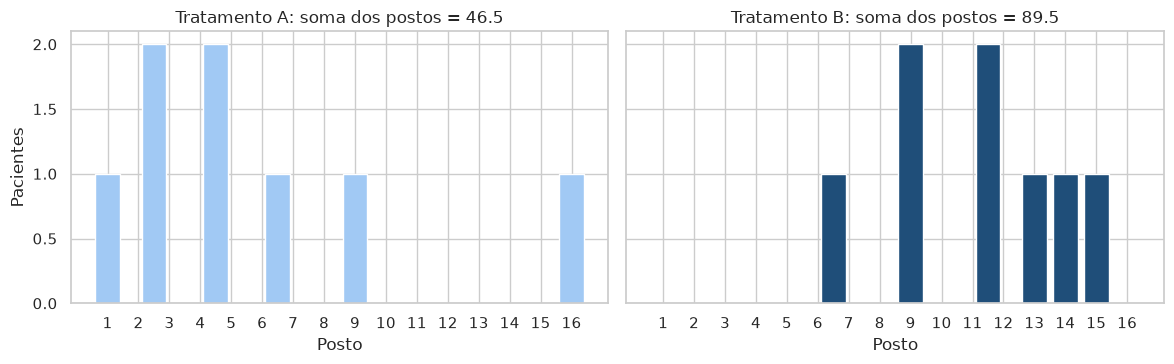

In [44]:
# histograma dos postos de cada tratamento
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True, sharey=True)

for ax, (group, color) in zip(axes, [("A", "#A1C9F4"), ("B", "#1F4E79")]):
    # pega os postos só do grupo atual
    ranks = ranked.loc[ranked["tratamento"] == group, "posto"]
    # como há postos fracionários (2.5, 11.5...), contamos cada valor exato
    # e desenhamos uma barra sobre ele, em vez de agrupar em faixas
    counts = ranks.value_counts()
    ax.bar(counts.index, counts.values, width=.8, color=color)
    ax.set(title=f"Tratamento {group}: soma dos postos = {ranks.sum():g}",
           xlabel="Posto", xticks=range(1, 17))

axes[0].set_ylabel("Pacientes")
plt.tight_layout()
plt.show()
# A concentra os postos baixos (tempos curtos) -> soma de postos menor

In [45]:
# soma dos postos de cada grupo (W) e U calculado pela fórmula
w_a = ranked.loc[ranked["tratamento"] == "A", "posto"].sum()
w_b = ranked.loc[ranked["tratamento"] == "B", "posto"].sum()
N = len(ranked)
# menor soma possível para A: se A ocupasse os postos 1, 2, ..., n_A -> n_A(n_A + 1)/2
minimum = n_a * (n_a + 1) / 2

# a soma de todos os postos de 1 a N é sempre N(N + 1)/2 = 136, com ou sem empates
print(f"W_A = {w_a} · W_B = {w_b} · total = {w_a + w_b} = N(N + 1)/2")
# atalho: U = W - mínimo possível. dá exatamente o mesmo U da contagem de duelos,
# sem precisar montar a matriz 8x8
print(f"U_A = {w_a} − {minimum} = {w_a - minimum}")
print(f"U_B = {w_b} − {minimum} = {w_b - minimum}")

W_A = 46.5 · W_B = 89.5 · total = 136.0 = N(N + 1)/2
U_A = 46.5 − 36.0 = 10.5
U_B = 89.5 − 36.0 = 53.5


### 3.9 O p-valor pela aproximação normal

In [ ]:
# os quatro passos da aproximação normal
# ideia: se H0 for verdade (tratamento não importa), U segue aproximadamente uma normal
# com média mu_U e desvio sigma_U calculamos o z de U_A e olhamos as caudas

# 1. média de U sob H0: metade dos duelos para cada lado
mu_u = n_a * n_b / 2
# 2. desvio-padrão de U sob H0, fórmula sem empates
sd_no_ties = np.sqrt(n_a * n_b * (N + 1) / 12)

# 3. correção para empates: value_counts conta quantas vezes cada valor aparece (t)
#    valores sem empate têm t = 1 e contribuem 1³ - 1 = 0
ties = ranked["dias"].value_counts()
tie_sum = (ties ** 3 - ties).sum()
# empates diminuem um pouco a variância de U
sd_u = np.sqrt(n_a * n_b / 12 * ((N + 1) - tie_sum / (N * (N - 1))))

# 4. padroniza: z = (U - média) / desvio, com correção de continuidade de ±0.5
#    (U é discreto e a normal é contínua np.sign escolhe o sinal que aproxima U do centro)
z = (u_a - mu_u + 0.5 * np.sign(mu_u - u_a)) / sd_u
# p bilateral: área da cauda esquerda além de |z|, vezes 2 (as duas caudas)
p = 2 * stats.norm.cdf(-abs(z))

print(f"1. μ_U = {mu_u}")
print(f"2. σ_U sem empates = {sd_no_ties:.2f}")
print(f"3. Σ(t³ − t) = {tie_sum} · σ_U com empates = {sd_u:.2f}")
print(f"4. Z = {z:.2f} · p = {p:.4f}")
# p ~ 0.027 < 0.05: agora SIM há evidência de diferença (o teste t não tinha detectado)

1. μ_U = 32.0
2. σ_U sem empates = 9.52
3. Σ(t³ − t) = 48 · σ_U com empates = 9.47
4. Z = -2.22 · p = 0.0265


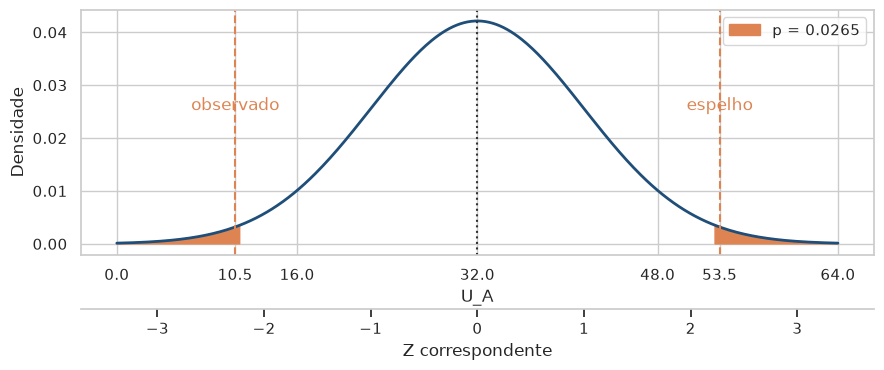

In [47]:
# curva normal de U sob H0, com as duas caudas do p-valor pintadas
grid = np.linspace(0, n_a * n_b, 400)               # U vai de 0 a 64
density = stats.norm.pdf(grid, mu_u, sd_u)          # normal com média mu_u e desvio sd_u
# valor "espelho" de U_A do outro lado do centro (teste bilateral olha os dois lados)
mirror = n_a * n_b - u_a

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(grid, density, color="#1F4E79", linewidth=2)
# caudas: tudo que é tão ou mais extremo que o observado (com o 0.5 da correção de continuidade)
tails = (grid <= u_a + 0.5) | (grid >= mirror - 0.5)
ax.fill_between(grid, density, where=tails, color="#DD8452", label=f"p = {p:.4f}")
# linhas tracejadas no valor observado e no espelho
for value, label in [(u_a, "observado"), (mirror, "espelho")]:
    ax.axvline(value, color="#DD8452", linestyle="--")
    ax.text(value, density.max() * 0.6, label, ha="center", color="#DD8452")
ax.axvline(mu_u, color="#333333", linestyle=":")    # centro da distribuição (32)
ax.set(xlabel="U_A", ylabel="Densidade", xticks=[0, 10.5, 16, 32, 48, 53.5, 64])
# secondary_xaxis cria um segundo eixo x embaixo que converte cada U no seu Z
# precisa de duas funções: U -> Z e Z -> U (a inversa)
z_axis = ax.secondary_xaxis(-0.22, functions=(lambda u: (u - mu_u) / sd_u,
                                              lambda v: v * sd_u + mu_u))
z_axis.set_xlabel("Z correspondente")
ax.legend()
plt.tight_layout()
plt.show()

In [48]:
# o mesmo teste de Mann-Whitney, agora pronto no scipy
# method="asymptotic" pede o p-valor pela aproximação normal, com correção para empates
# e correção de continuidade -> deve bater com a conta manual acima
mw_uti = stats.mannwhitneyu(group_a, group_b, method="asymptotic")

report("Mann-Whitney", mw_uti, stat="U")

Mann-Whitney: U = 10.500 · p = 0.027


In [ ]:
# o mesmo teste com as três hipóteses alternativas possíveis
for alternative, h1 in [("two-sided", "A e B diferem"), ("less", "A tende a tempos menores"), ("greater", "A tende a tempos maiores")]:
  result = stats.mannwhitneyu(group_a, group_b, alternative=alternative, method="asymptotic")
  # :>9 alinha à direita em 9 caracteres e :<25 alinha à esquerda em 25 (só estética)
  print(f"{alternative:>9} · H1: {h1:<25} · p = {result.pvalue:.4f}")
# "less" tem metade do p bilateral (só uma cauda) "greater" fica perto de 1
# porque os dados apontam justamente para o lado contrário

two-sided · H1: A e B diferem             · p = 0.0265
     less · H1: A tende a tempos menores  · p = 0.0133
  greater · H1: A tende a tempos maiores  · p = 0.9899


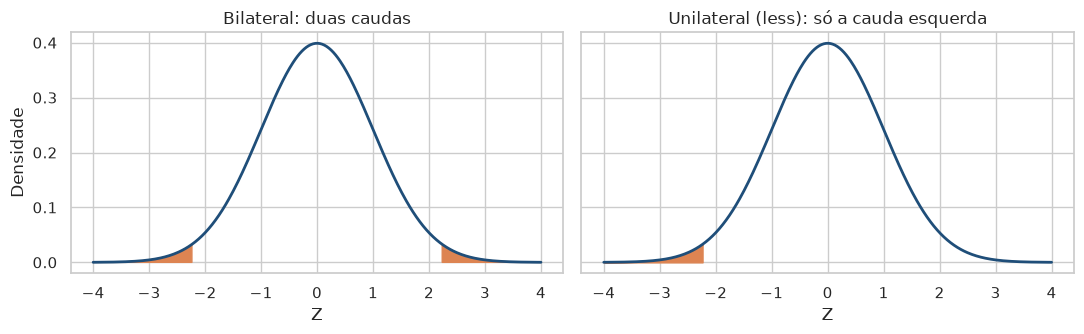

In [50]:
# área do p-valor no teste bilateral e no unilateral à esquerda
grid = np.linspace(-4, 4, 400)
density = stats.norm.pdf(grid)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
# para cada painel: o eixo, quais pontos pintar e o título
for ax, tails, title in [
    (axes[0], np.abs(grid) >= abs(z), "Bilateral: duas caudas"),          # |Z| >= |z|
    (axes[1], grid <= -abs(z), "Unilateral (less): só a cauda esquerda"),  # Z <= -|z|
]:
    ax.plot(grid, density, color="#1F4E79", linewidth=2)
    ax.fill_between(grid, density, where=tails, color="#DD8452")
    ax.set(title=title, xlabel="Z")
axes[0].set_ylabel("Densidade")
plt.tight_layout()
plt.show()

## 4. Caso 1. Mann-Whitney em um teste A/B

In [51]:
# segundos até o primeiro clique em cada layout de um site (8 usuários por layout)
# de novo, A tem um valor extremo (14.0)
layout_a = [2.1, 2.8, 3.0, 3.4, 3.7, 4.2, 4.6, 14.0]
layout_b = [3.9, 4.8, 5.0, 5.8, 6.1, 6.9, 7.7, 9.5]

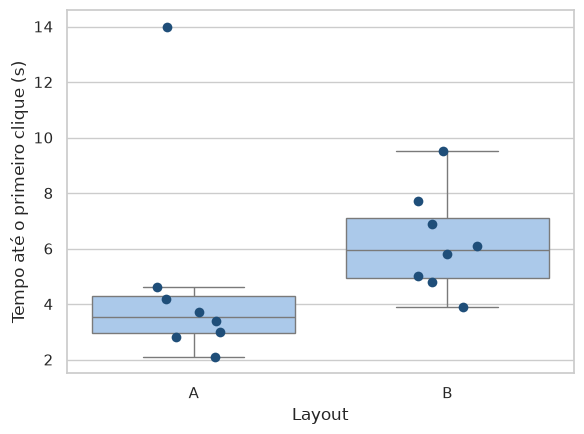

In [ ]:
# tempo até o primeiro clique por layout
# tabela longa: uma linha por usuário
clicks = pd.DataFrame(
    {"layout": ["A"] * 8 + ["B"] * 8, "segundos": layout_a + layout_b}
)

fig, ax = plt.subplots(figsize=(6, 4.5))
# boxplot sem os outliers (showfliers=False), porque os pontos vêm do stripplot logo abaixo
sns.boxplot(data=clicks, x="layout", y="segundos", color="#A1C9F4",
            showfliers=False, ax=ax)
# stripplot desenha cada usuário como um ponto jitter espalha um pouco na horizontal
sns.stripplot(data=clicks, x="layout", y="segundos", color="#1F4E79",
              size=7, jitter=.15, ax=ax)
ax.set(xlabel="Layout", ylabel="Tempo até o primeiro clique (s)")
plt.tight_layout()
plt.show()

In [ ]:
# função que faz todo o passo a passo do Mann-Whitney: postos, U, z, p-valor e δ de Cliff
def mann_whitney_steps(a, b):
    # junta os dois grupos (os n_a primeiros são de A, o resto de B)
    values = pd.Series(list(a) + list(b))
    # postos com média nos empates
    ranks = values.rank(method="average")
    n_a, n_b, N = len(a), len(b), len(values)
    # soma dos postos de A (as n_a primeiras posições) e U pela fórmula do atalho
    w_a = ranks[:n_a].sum()
    u_a = w_a - n_a * (n_a + 1) / 2
    # correção de empates no desvio-padrão
    ties = values.value_counts()
    tie_term = (ties ** 3 - ties).sum() / (N * (N - 1))
    sd_u = np.sqrt(n_a * n_b / 12 * ((N + 1) - tie_term))
    mu_u = n_a * n_b / 2
    # z com correção de continuidade
    z = (u_a - mu_u + 0.5 * np.sign(mu_u - u_a)) / sd_u
    # δ de Cliff = (U_A - U_B) / (n_A n_B), com U_B = n_A n_B - U_A -> tamanho de efeito
    # vai de -1 (todo A < todo B) a +1 (todo A > todo B) 0 = sem tendência
    delta = (2 * u_a - n_a * n_b) / (n_a * n_b)
    print(f"W_A = {w_a:g} · W_B = {ranks[n_a:].sum():g} · U_A = {u_a:g} · "
          f"Z = {z:.2f} · p = {2 * stats.norm.cdf(-abs(z)):.4f} · δ = {delta:.2f}")

# roda para o teste de layout e para os dados da UTI (este deve repetir os resultados da seção 3)
mann_whitney_steps(layout_a, layout_b)
mann_whitney_steps(days_a, days_b)

W_A = 46 · W_B = 90 · U_A = 10 · Z = -2.26 · p = 0.0239 · δ = -0.69
W_A = 46.5 · W_B = 89.5 · U_A = 10.5 · Z = -2.22 · p = 0.0265 · δ = -0.67


In [54]:
# Mann-Whitney e Welch no teste de layout, lado a lado
mw_layout = stats.mannwhitneyu(layout_a, layout_b, method="asymptotic")

welch_layout = stats.ttest_ind(layout_a, layout_b, equal_var=False)

report("Mann-Whitney", mw_layout, stat="U")
report("t de Welch", welch_layout, stat="t")
# mesma história da UTI: Mann-Whitney detecta diferença (p < 0.05),
# o t de Welch não, porque o valor extremo (14.0) infla a variância

Mann-Whitney: U = 10.000 · p = 0.024
t de Welch: t = -0.995 · gl = 9.926 · p = 0.343


## 5. Caso 2. Pearson e Spearman

In [ ]:
# carrega a base de carros (mtcars): consumo (mpg), potência (hp) etc.
# obs.: no site o caminho é "mtcars/data/mtcars.csv" aqui o csv está na pasta data/ da aula
mtcars = pd.read_csv("data/mtcars.csv")

### 5.1 Os dois coeficientes

In [56]:
# Pearson nos valores, Spearman, e Pearson calculado sobre os postos
# .rank() por padrão usa o posto médio nos empates, como na seção 3
ranks_hp = mtcars["hp"].rank()
ranks_mpg = mtcars["mpg"].rank()

# Pearson mede relação LINEAR entre os valores
pearson_values = stats.pearsonr(mtcars["hp"], mtcars["mpg"])
# Spearman mede relação MONOTÔNICA (sempre sobe ou sempre desce, mesmo que curvada)
spearman = stats.spearmanr(mtcars["hp"], mtcars["mpg"])
# truque: Spearman é exatamente o Pearson aplicado aos postos
pearson_ranks = stats.pearsonr(ranks_hp, ranks_mpg)

report("Pearson (valores)", pearson_values, stat="r")
report("Spearman", spearman, stat="ρ")
report("Pearson (postos)", pearson_ranks, stat="r")
# as duas últimas linhas dão o mesmo número, confirmando o truque

Pearson (valores): r = -0.776 · p < 0.001
Spearman: ρ = -0.895 · p < 0.001
Pearson (postos): r = -0.895 · p < 0.001


In [ ]:
# fórmula clássica de Spearman usando as diferenças de postos
# d = diferença entre o posto de hp e o posto de mpg de cada carro
d = ranks_hp - ranks_mpg
n = len(mtcars)

print(f"Σd² = {(d ** 2).sum()}")
# ρ = 1 - 6Σd² / (n(n² - 1))
# essa fórmula é exata só sem empates como mtcars tem empates, sai um pouco diferente (-0.891 vs -0.895)
print(f"ρ pela fórmula = {1 - 6 * (d ** 2).sum() / (n * (n ** 2 - 1)):.3f}")

Σd² = 10315.5
ρ pela fórmula = -0.891


### 5.2 Valores e postos lado a lado

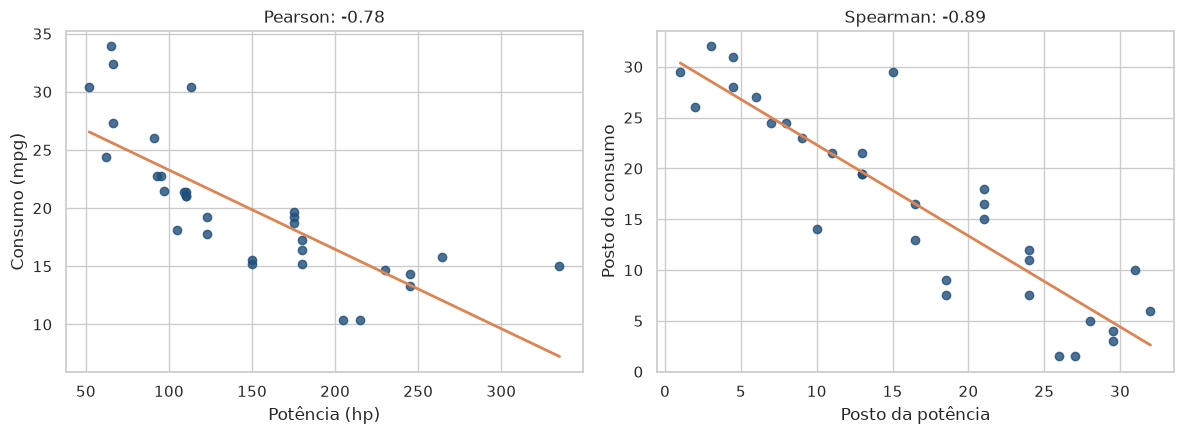

In [ ]:
# dispersão dos valores (esquerda) e dos postos (direita), com a reta de mínimos quadrados
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# cada painel: (x, y, rótulo x, rótulo y, nome do coeficiente)
panels = [
  (mtcars["hp"], mtcars["mpg"], "Potência (hp)", "Consumo (mpg)", "Pearson"),
  (ranks_hp, ranks_mpg, "Posto da potência", "Posto do consumo", "Spearman"),
]

for ax, (x, y, xlabel, ylabel, name) in zip(axes, panels):
  # np.polyfit com deg=1 ajusta uma reta y = intercept + slope * x (devolve [slope, intercept])
  slope, intercept = np.polyfit(x, y, deg=1)
  grid = np.linspace(x.min(), x.max(), 100)
  ax.scatter(x, y, color="#1F4E79", alpha=.8)
  ax.plot(grid, intercept + slope * grid, color="#DD8452", linewidth=2)
  # o título mostra o Pearson de cada painel no painel dos postos ele É o Spearman
  ax.set(xlabel=xlabel, ylabel=ylabel, title=f"{name}: {stats.pearsonr(x, y).statistic:.2f}")

plt.tight_layout()
plt.show()
# nos valores a relação é curvada (a reta se ajusta mal) nos postos ela fica quase reta,
# por isso o Spearman (-0.89) é mais forte que o Pearson (-0.78)

# 6. Questões para casa

1. No exemplo do hospital, meça o tempo em horas e, depois, aplique o log aos dias. Em cada caso, o p-valor do Welch muda? E o do Mann-Whitney? Explique o resultado pela ordem dos valores.

In [ ]:
# os mesmos pacientes em três escalas: dias (original), horas (dias x 24) e log dos dias
# np.array permite multiplicar e aplicar log em todos os valores de uma vez
a = np.array(days_a)
b = np.array(days_b)

scales_hw = {
  "dias": (a, b),
  "horas": (a * 24, b * 24), # transformação linear: só muda a unidade
  "log(dias)": (np.log(a), np.log(b)), # transformação não linear, mas sempre crescente
}

for name, (x, y) in scales_hw.items():
  welch = stats.ttest_ind(x, y, equal_var=False)
  mw = stats.mannwhitneyu(x, y, method="asymptotic")
  report(f"Welch ({name})", welch, stat="t")
  report(f"Mann-Whitney ({name})", mw, stat="U")
  print()

Welch (dias): t = 0.767 · gl = 7.023 · p = 0.468
Mann-Whitney (dias): U = 10.500 · p = 0.027

Welch (horas): t = 0.767 · gl = 7.023 · p = 0.468
Mann-Whitney (horas): U = 10.500 · p = 0.027

Welch (log(dias)): t = -0.731 · gl = 7.478 · p = 0.487
Mann-Whitney (log(dias)): U = 10.500 · p = 0.027



In [ ]:
# conferindo a explicação: os postos são idênticos nas três escalas
# se a ordem dos valores não muda, o rank de cada paciente também não muda
pd.DataFrame({
  name: pd.Series(np.concatenate([x, y])).rank()
  for name, (x, y) in scales_hw.items()
}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
dias,1.0,2.5,2.5,4.5,4.5,6.5,9.0,16.0,6.5,9.0,9.0,11.5,11.5,13.0,14.0,15.0
horas,1.0,2.5,2.5,4.5,4.5,6.5,9.0,16.0,6.5,9.0,9.0,11.5,11.5,13.0,14.0,15.0
log(dias),1.0,2.5,2.5,4.5,4.5,6.5,9.0,16.0,6.5,9.0,9.0,11.5,11.5,13.0,14.0,15.0


**Resposta:**

- **Horas:** nada muda. O Welch dá o mesmo t (0,767) e o mesmo p (0,468). Multiplicar por 24 multiplica as médias e os desvios-padrão pelo mesmo número, e esse fator se cancela no t. O Mann-Whitney também fica igual (U = 10,5, p = 0,027).

- **log(dias):** o Welch muda. O t passa de +0,77 para −0,73, ou seja, a média de A deixa de ser maior que a de B. O p vai de 0,468 para 0,487. O log "encolhe" o 120 (log 120 ≈ 4,8), mas não é uma transformação linear, então as médias e as variâncias mudam de forma diferente. Mesmo assim o teste continua não significativo, porque o paciente extremo ainda deixa a variância de A grande. O Mann-Whitney não muda nada (U = 10,5, p = 0,0265).

- Tanto ×24 quanto log são transformações monotônicas crescentes, se um paciente ficou mais tempo que outro em dias, também ficou mais tempo em horas e em log(dias). A ordem dos 16 pacientes é a mesma nas três escalas, então os postos são os mesmos (veja a tabela acima). O Mann-Whitney só usa os postos, por isso dá sempre o mesmo resultado. O Welch usa os valores em si (médias e variâncias), então depende da escala. Uma mudança linear de unidade não o altera, mas o log altera.

2. Use `mann_whitney_steps` para comparar a massa corporal de pinguins machos e fêmeas da espécie Adelie (Aula 8). Compare o p-valor com o do teste de Welch e o δ de Cliff com a diferença de médias.

In [67]:
# a base de pinguins está na pasta da Aula 8
penguins = pd.read_csv("data/penguins.csv")

# só Adelie, removendo quem não tem massa ou sexo registrado
adelie = (
  penguins
  .query("species == 'Adelie'")
  .dropna(subset=["body_mass", "sex"])
)
male = adelie.loc[adelie["sex"] == "male", "body_mass"]
female = adelie.loc[adelie["sex"] == "female", "body_mass"]

# resumo por sexo: tamanho, média, desvio e mediana
adelie.groupby("sex").body_mass.agg(n="size", média="mean", dp="std", mediana="median").round(1)

,n,média,dp,mediana
sex,,,,
female,73,3368.8,269.4,3400.0
male,73,4043.5,346.8,4000.0


In [ ]:
# Mann-Whitney passo a passo (machos como grupo "A" δ > 0 significa machos mais pesados)
mann_whitney_steps(male, female)
# a função arredonda o p para 4 casas (aparece 0.0000) o scipy mostra o valor real
print(f"p do Mann-Whitney (scipy) = {stats.mannwhitneyu(male, female, method='asymptotic').pvalue:.1e}")

# Welch para comparar os p-valores
welch_sex = stats.ttest_ind(male, female, equal_var=False)
report("t de Welch", welch_sex, stat="t")
print(f"p do Welch = {welch_sex.pvalue:.1e}")

# diferença de médias, em gramas
print(f"diferença de médias (machos − fêmeas) = {male.mean() - female.mean():.1f} g")

W_A = 7719.5 · W_B = 3011.5 · U_A = 5018.5 · Z = 9.22 · p = 0.0000 · δ = 0.88
p do Mann-Whitney (scipy) = 3.1e-20
t de Welch: t = 13.126 · gl = 135.7 · p < 0.001
p do Welch = 6.4e-26
diferença de médias (machos − fêmeas) = 674.7 g


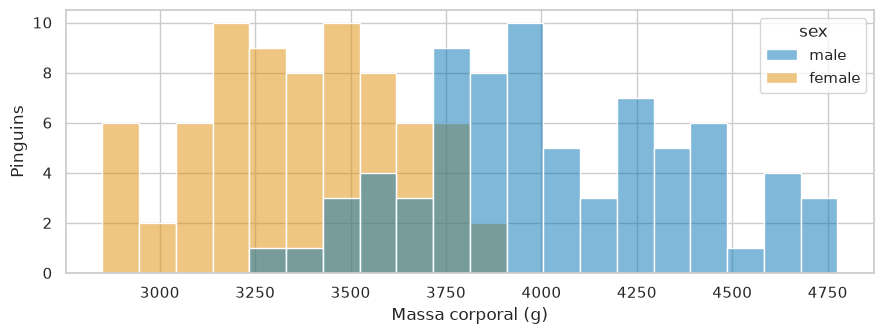

P(macho > fêmea) = 0.942


In [63]:
# para entender o δ: quanto as duas distribuições se sobrepõem?
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(data=adelie, x="body_mass", hue="sex", bins=20, ax=ax)
ax.set(xlabel="Massa corporal (g)", ylabel="Pinguins")
plt.tight_layout()
plt.show()

# proporção dos pares (macho, fêmea) em que o macho é mais pesado (empate conta meio)
duels_sex = np.sign(np.subtract.outer(male.to_numpy(), female.to_numpy()))
print(f"P(macho > fêmea) = {((duels_sex > 0).sum() + 0.5 * (duels_sex == 0).sum()) / duels_sex.size:.3f}")

**Resposta:**

- **p-valores:** os dois testes concordam. Os dois p-valores são minúsculos: cerca de 3·10⁻²⁰ no Mann-Whitney e 6·10⁻²⁶ no Welch. Aqui os dados não têm outliers como os do hospital, e com 73 pinguins por grupo as duas abordagens enxergam a mesma diferença. O Welch dá um p ainda menor porque, quando os dados se comportam bem, usar os valores (e não só a ordem) aproveita mais informação.

- **δ de Cliff × diferença de médias:** as duas medidas respondem a perguntas diferentes.
  - A diferença de médias (≈ 675 g) diz quanto os machos pesam a mais, em gramas. Depende da unidade.
  - O δ de Cliff (≈ 0,88) não tem unidade e diz com que frequência um macho é mais pesado que uma fêmea. Ele vai de −1 a +1. δ = 0,88 equivale a P(macho > fêmea) ≈ 0,94: sorteando um macho e uma fêmea ao acaso, o macho é mais pesado em cerca de 94% das vezes. É um efeito muito grande (|δ| > 0,47 já costuma ser chamado de grande). As distribuições se sobrepõem só um pouco, na faixa de ~3300 a 3900 g.

3. No mtcars, compare Pearson e Spearman entre o peso (`wt`) e o consumo (`mpg`). Os coeficientes divergem tanto quanto no caso 2? O que isso indica sobre a forma da relação?

In [64]:
# Pearson (relação linear) e Spearman (relação monotônica) entre peso e consumo
report("Pearson wt × mpg", stats.pearsonr(mtcars["wt"], mtcars["mpg"]), stat="r")
report("Spearman wt × mpg", stats.spearmanr(mtcars["wt"], mtcars["mpg"]), stat="ρ")

# o caso 2 da aula (potência × consumo), para comparar
report("Pearson hp × mpg", stats.pearsonr(mtcars["hp"], mtcars["mpg"]), stat="r")
report("Spearman hp × mpg", stats.spearmanr(mtcars["hp"], mtcars["mpg"]), stat="ρ")

Pearson wt × mpg: r = -0.868 · p < 0.001
Spearman wt × mpg: ρ = -0.886 · p < 0.001
Pearson hp × mpg: r = -0.776 · p < 0.001
Spearman hp × mpg: ρ = -0.895 · p < 0.001


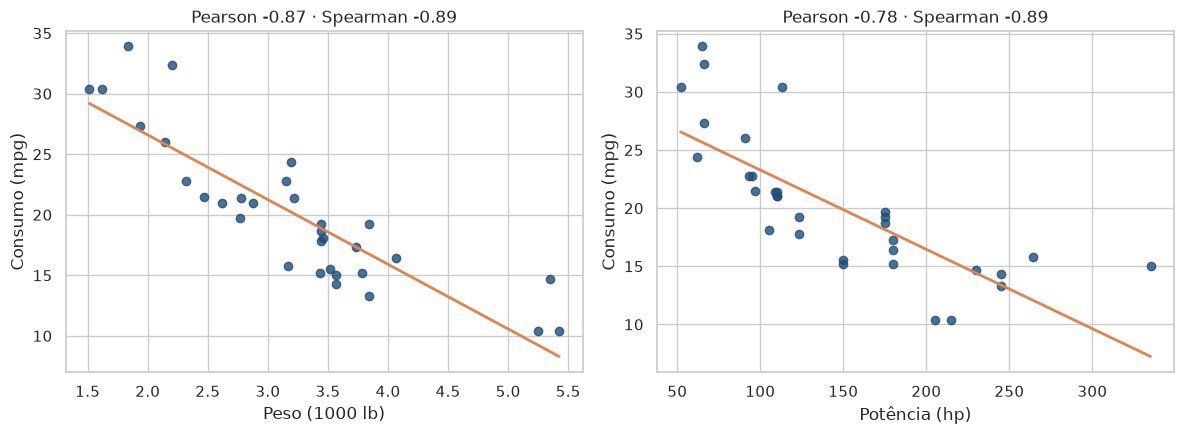

In [ ]:
# dispersão de wt × mpg e hp × mpg, com a reta de mínimos quadrados
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, (col, xlabel) in zip(axes, [("wt", "Peso (1000 lb)"), ("hp", "Potência (hp)")]):
    x, y = mtcars[col], mtcars["mpg"]
    slope, intercept = np.polyfit(x, y, deg=1)
    grid = np.linspace(x.min(), x.max(), 100)
    ax.scatter(x, y, color="#1F4E79", alpha=.8)
    ax.plot(grid, intercept + slope * grid, color="#DD8452", linewidth=2)
    ax.set(xlabel=xlabel, ylabel="Consumo (mpg)", title=f"Pearson {stats.pearsonr(x, y).statistic:.2f} · "f"Spearman {stats.spearmanr(x, y).statistic:.2f}")

plt.tight_layout()
plt.show()

**Resposta:**

- **Peso × consumo:** Pearson = −0,87 e Spearman = −0,89. Os dois são fortes e negativos (carros mais pesados fazem menos milhas por galão) e diferem só 0,02
- **No caso 2 (potência × consumo):** Pearson = −0,78 e Spearman = −0,89, uma diferença de 0,12, seis vezes maior.
- Quando os dois coeficientes ficam quase iguais, a relação monotônica é também praticamente linear. Os pontos de wt × mpg seguem bem uma reta, e o Pearson não perde nada em relação ao Spearman. Já em hp × mpg, a relação é monotônica mas curvada o consumo cai rápido entre as potências baixas e depois se estabiliza. Há ainda alguns carros muito potentes que ficam longe da reta. A ordem continua bem consistente (Spearman alto), mas a reta se ajusta pior (Pearson menor). Ou seja, quanto maior a diferença entre Spearman e Pearson, mais a relação se afasta de uma linha reta, seja por curvatura ou por valores extremos.